## Step 1: load the Sephora files and describe ratings by skin type

 Load the three clean Sephora files and keep only reviews that have a skin type. Then compare the four skin types descriptively before any test: number of reviews, mean and median rating, share of 5-star and of 1-2 star reviews, and share who recommend the product.

In [2]:
import pandas as pd, numpy as np
from scipy import stats

# 1. Load the clean files made in 03_clean_sephora
rev  = pd.read_csv("../data/clean/sephora_reviews.csv", dtype={"author_id": str},
                   parse_dates=["submission_time"])
prod = pd.read_csv("../data/clean/sephora_products.csv")
ing  = pd.read_csv("../data/clean/sephora_ingredients.csv")

# 2. Only reviews with a skin type (the base for H2 and H3)
typed = rev.dropna(subset=["skin_type"]).copy()
print("reviews with skin type:", len(typed), "| authors:", typed["author_id"].nunique())

# 3. Descriptive table by skin type
desc = typed.groupby("skin_type").agg(
    n_reviews   = ("rating", "size"),
    mean_rating = ("rating", "mean"),
    median      = ("rating", "median"),
    pct_5_star  = ("rating", lambda s: (s == 5).mean() * 100),
    pct_1_2     = ("rating", lambda s: (s <= 2).mean() * 100),
    pct_recomm  = ("is_recommended", "mean"),        # is_recommended is 1/0, missing is ignored
).round(2)
desc["pct_recomm"] = typed.groupby("skin_type")["is_recommended"].mean().mul(100).round(1)   # percent with one decimal
desc

reviews with skin type: 982854 | authors: 446491


,n_reviews,mean_rating,median,pct_5_star,pct_1_2,pct_recomm
skin_type,,,,,,
combination,544513,4.31,5.0,63.69,9.97,84.5
dry,185937,4.29,5.0,64.04,10.82,83.6
normal,131910,4.28,5.0,63.55,10.81,83.4
oily,120494,4.27,5.0,62.84,11.02,83.4


**Findings: ratings by skin type (descriptive)**
- 982,854 reviews with a skin type, written by 446,491 authors (about 2.2 reviews per author).
- Mean ratings are almost identical: combination 4.31, dry 4.29, normal 4.28, oily 4.27; median 5 in all groups.

## Step 2: H2 test (do ratings differ between skin types?)

 - H2. Ratings are very skewed (64% five stars), so I use rank-based tests, not means. Kruskal-Wallis tests all four skin types together. Because there are almost a million reviews, the p-value will always be tiny, so I also report the effect size (epsilon squared: 0.01 = small, 0.06 = medium, 0.14 = large). Then I compare each pair with Mann-Whitney U and report the probability of superiority (0.5 = no difference). Reviews are not fully independent (one person can write several), which I note as a limitation.

In [3]:
# 1. Kruskal-Wallis across the four skin types
groups = [g["rating"].values for _, g in typed.groupby("skin_type")]
H, p = stats.kruskal(*groups)
n = len(typed)
eps2 = H / (n - 1)                                   # epsilon squared = effect size of Kruskal-Wallis
print(f"Kruskal-Wallis: H = {H:.1f}, p = {p:.2e}, epsilon^2 = {eps2:.4f}")

# 2. Pairwise Mann-Whitney U with probability of superiority
from itertools import combinations
rows = []
for a, b in combinations(sorted(typed["skin_type"].unique()), 2):
    x = typed.loc[typed["skin_type"] == a, "rating"].values
    y = typed.loc[typed["skin_type"] == b, "rating"].values
    U, p_ab = stats.mannwhitneyu(x, y, alternative="two-sided", method="asymptotic")
    rows.append({"group A": a, "group B": b,
                 "P(A rated higher than B)": U / (len(x) * len(y)),   # 0.5 = no difference
                 "p (raw)": p_ab})
pairs = pd.DataFrame(rows)
pairs["p (Bonferroni, x6)"] = (pairs["p (raw)"] * len(pairs)).clip(upper=1)   # 6 comparisons
pairs.round(4)

Kruskal-Wallis: H = 66.9, p = 1.94e-14, epsilon^2 = 0.0001


,group A,group B,P(A rated higher than B),p (raw),"p (Bonferroni, x6)"
0,combination,dry,0.5005,0.4560,1.0000
1,combination,normal,0.5027,0.0003,0.0019
2,combination,oily,0.5061,0.0000,0.0000
3,dry,normal,0.5022,0.0124,0.0744
4,dry,oily,0.5056,0.0000,0.0000
5,normal,oily,0.5034,0.0007,0.0041


**Findings H2: do ratings differ between skin types?**
- Kruskal-Wallis test: H = 66.9, p = 1.9e-14, but epsilon squared = 0.0001, which is negligible (small effect starts at 0.01).
- Pairwise Mann-Whitney tests (Bonferroni, 6 comparisons): oily-skin reviewers rate slightly lower than the other three groups; the probability of superiority is 0.50-0.51 in all pairs (0.5 = no difference).
- With almost a million reviews, even tiny differences are significant, so the effect size is what counts: **skin type alone does not meaningfully change ratings.**
- Limitation: reviews are not independent (446,491 authors wrote 982,854 reviews).

## Step 3: ingredient functions and counts per product

Take the ingredient functions from the database (CosIng) and count, for each product, how many different ingredients are humectants, emollients and occlusives. Each ingredient is counted once per product. First I list which function names exist, because CosIng also uses combined names like “SKIN CONDITIONING - EMOLLIENT”.

In [4]:
import os
from dotenv import load_dotenv
from sqlalchemy import create_engine

# 1. Functions of each CosIng ingredient from MySQL
load_dotenv("../.env", override=True)
engine = create_engine(os.getenv("CON_STRING"))
funcs = pd.read_sql("SELECT ingredient_id, function_name FROM ingredient_functions", engine)
funcs["function_name"] = funcs["function_name"].str.upper().str.strip()

# 2. Which function names contain our three words? (check before counting)
mask = funcs["function_name"].str.contains("HUMECTANT|EMOLLIENT|OCCLUSIVE")
print(funcs[mask]["function_name"].value_counts())

# 3. Count different ingredients of one function per product
def count_function(pattern, label):
    ids = funcs.loc[funcs["function_name"].str.contains(pattern), "ingredient_id"].unique()
    hit = ing[ing["ingredient_id"].isin(ids)].drop_duplicates(["product_id", "ingredient_id"])   # each ingredient once per product
    return hit.groupby("product_id").size().rename(label)

feat = pd.DataFrame(index=ing["product_id"].unique())               # only products that have an ingredient list
feat.index.name = "product_id"
for pattern, label in [("HUMECTANT", "n_humectants"), ("EMOLLIENT", "n_emollients"), ("OCCLUSIVE", "n_occlusives")]:
    feat = feat.join(count_function(pattern, label))
feat = feat.fillna(0).astype(int)                                    # no hit = 0
feat["n_ingredients"] = ing.groupby("product_id").size()             # list length, for context

print(len(feat), "products")
print(feat.describe().round(1))
feat.head()

function_name
SKIN CONDITIONING - EMOLLIENT    3339
HUMECTANT                        2089
SKIN CONDITIONING - HUMECTANT     215
SKIN CONDITIONING - OCCLUSIVE      26
Name: count, dtype: int64
2286 products
       n_humectants  n_emollients  n_occlusives  n_ingredients
count        2286.0        2286.0        2286.0         2286.0
mean            4.0           5.4           1.0           38.3
std             3.2           4.6           1.0           29.1
min             0.0           0.0           0.0            1.0
25%             2.0           2.0           0.0           22.0
50%             3.0           5.0           1.0           33.0
75%             5.0           8.0           2.0           47.0
max            23.0          36.0           4.0          421.0


,n_humectants,n_emollients,n_occlusives,n_ingredients
product_id,,,,
P439055,2,7,2,42
P421277,4,5,3,38
P467602,7,8,0,64
P432045,3,4,2,37
P311143,2,4,0,28


In [5]:
# The 30 most common function names in CosIng (to see what else is available)
funcs["function_name"].value_counts().head(30)

function_name
SKIN CONDITIONING                    13035
SKIN CONDITIONING - EMOLLIENT         3339
HAIR CONDITIONING                     3332
SURFACTANT - CLEANSING                3073
SURFACTANT - EMULSIFYING              2746
PERFUMING                             2711
ANTIOXIDANT                           2559
SKIN PROTECTING                       2356
HUMECTANT                             2089
FRAGRANCE                             1405
CLEANSING                             1380
VISCOSITY CONTROLLING                 1375
FILM FORMING                          1229
ANTISTATIC                            1071
ANTIMICROBIAL                          950
SOLVENT                                635
EMULSION STABILISING                   620
SKIN CONDITIONING - MISCELLANEOUS      615
NOT REPORTED                           565
ASTRINGENT                             544
BINDING                                535
SURFACTANT - FOAM BOOSTING             448
HAIR DYEING                            4

## Step 4: link features to ratings (one row per product and skin type)

- Add the anti-sebum count and the share of each function in the ingredient list (this removes the effect of long lists). Then build one row per product and skin type with the mean rating of that group of reviewers. I use the product as the unit, not the single review, so one popular product with 10,000 reviews cannot dominate. Only groups with at least 10 reviews are used, because a mean of 2 reviews is not reliable.

In [6]:
# 1. Fourth feature: anti-sebum (oily-skin function)
feat["n_antisebum"] = count_function("ANTI-SEBUM", "n_antisebum").reindex(feat.index).fillna(0).astype(int)

# 2. Share of each function in the ingredient list (removes the effect of list length)
for c in ["n_humectants", "n_emollients", "n_occlusives", "n_antisebum"]:
    feat["share_" + c[2:]] = feat[c] / feat["n_ingredients"]

# 3. One row per product and skin type: mean rating and number of reviews
pt = typed.groupby(["product_id", "skin_type"])["rating"].agg(n="size", mean_rating="mean").reset_index()
pt = pt[pt["n"] >= 10]                                    # at least 10 reviews in the group
pt = pt.merge(feat.reset_index(), on="product_id")        # add the ingredient features

# 4. Checks
print("rows:", len(pt), "| products:", pt["product_id"].nunique())
print(pt.groupby("skin_type").size())
print(pt[["share_humectants", "share_emollients", "share_occlusives", "share_antisebum"]].describe().round(3))

rows: 6226 | products: 1862
skin_type
combination    1860
dry            1557
normal         1456
oily           1353
dtype: int64
       share_humectants  share_emollients  share_occlusives  share_antisebum
count          6226.000          6226.000          6226.000         6226.000
mean              0.104             0.145             0.030            0.002
std               0.071             0.113             0.037            0.017
min               0.000             0.000             0.000            0.000
25%               0.056             0.065             0.000            0.000
50%               0.097             0.136             0.022            0.000
75%               0.143             0.205             0.045            0.000
max               0.400             1.000             0.375            0.333


Step 5: H3 test

- H3. For each skin type I compute the Spearman correlation between the share of a function in the ingredient list and the mean rating of that product (rank-based, because ratings are skewed). A positive rho means “more of this function, better rating”. My prediction was: humectants and emollients help dry skin more than oily skin, and anti-sebum ingredients help oily skin more than dry skin. To test the difference, I take the products that have at least 10 dry and 10 oily reviews (the same products in both groups) and bootstrap the difference between the two correlations (rho dry minus rho oily) 1,000 times. If the 95% interval does not include 0, the difference is supported.

In [7]:
from scipy.stats import spearmanr

feats = {"share_humectants": "humectants", "share_emollients": "emollients",
         "share_occlusives": "occlusives", "share_antisebum": "anti-sebum"}
skin_types = ["combination", "dry", "normal", "oily"]

# 1. Spearman correlation per feature and skin type (function share vs mean rating of the product)
rows = []
for f, name in feats.items():
    for st in skin_types:
        d = pt[pt["skin_type"] == st]
        rho, p = spearmanr(d[f], d["mean_rating"])
        rows.append({"feature": name, "skin_type": st, "n_products": len(d), "rho": rho, "p": p})
res = pd.DataFrame(rows)
print(res.pivot(index="feature", columns="skin_type", values="rho").round(3))

# 2. Same products for dry and oily (needed for a fair comparison)
wide = pt.pivot(index="product_id", columns="skin_type", values="mean_rating")[["dry", "oily"]].dropna()
wide = wide.join(feat[list(feats)], how="left")
print("\nproducts with >=10 dry AND >=10 oily reviews:", len(wide))

# 3. Bootstrap of the difference rho(dry) - rho(oily)
rng = np.random.default_rng(42)                                  # fixed seed = same result every time
def diff_rho(d, f):
    return spearmanr(d[f], d["dry"])[0] - spearmanr(d[f], d["oily"])[0]

out = []
for f, name in feats.items():
    obs = diff_rho(wide, f)                                       # observed difference
    boots = [diff_rho(wide.sample(len(wide), replace=True, random_state=int(rng.integers(1_000_000_000))), f)
             for _ in range(1000)]                                # 1000 resamples of the products
    lo, hi = np.percentile(boots, [2.5, 97.5])                    # 95% interval
    out.append({"feature": name,
                "rho dry": spearmanr(wide[f], wide["dry"])[0],
                "rho oily": spearmanr(wide[f], wide["oily"])[0],
                "difference (dry - oily)": obs, "95% CI low": lo, "95% CI high": hi,
                "CI excludes 0": (lo > 0) or (hi < 0)})
pd.DataFrame(out).round(3)

skin_type   combination    dry  normal   oily
feature                                      
anti-sebum       -0.011 -0.015  -0.036  0.011
emollients        0.036  0.014   0.005 -0.012
humectants       -0.028 -0.041  -0.022 -0.014
occlusives        0.113  0.110   0.087  0.118

products with >=10 dry AND >=10 oily reviews: 1306


,feature,rho dry,rho oily,difference (dry - oily),95% CI low,95% CI high,CI excludes 0
0,humectants,-0.044,-0.012,-0.032,-0.073,0.011,False
1,emollients,0.022,-0.017,0.039,-0.004,0.082,False
2,occlusives,0.108,0.116,-0.008,-0.051,0.036,False
3,anti-sebum,-0.019,0.010,-0.029,-0.067,0.009,False


**Findings H2 and H3: skin type, ingredient functions and ratings**
- H2: Ratings differ only negligibly between skin types (epsilon squared 0.0001). Oily-skin reviewers rate very slightly lower.
- H3: I predicted (before testing) that humectant- and emollient-rich products are rated better by dry than by oily skin, and anti-sebum products better by oily than by dry skin. This was **not supported**: for all four functions the 95% bootstrap interval of the difference in Spearman correlations (dry minus oily, 1,306 products with at least 10 reviews in both groups) includes 0, and all correlations are small (|rho| < 0.12).
- Occlusive ingredients show a small positive association with ratings (rho about 0.11), but equally in all four skin types, so it is not skin-type specific (probably a product-type effect).
- Limits: function labels from CosIng say nothing about concentration; ratings also depend on price, brand, texture and product type; anti-sebum ingredients are rare (270 in CosIng).
- Conclusion: **broad ingredient functions do not explain skin-type-specific ratings in this data.**

## Step 6: save the chart and the Tableau file

- One chart that shows the null result honestly (difference between dry and oily with its 95% interval, zero line marked), and one clean file for the Tableau “fit” page: one row per product and skin type, with product details and ingredient features.

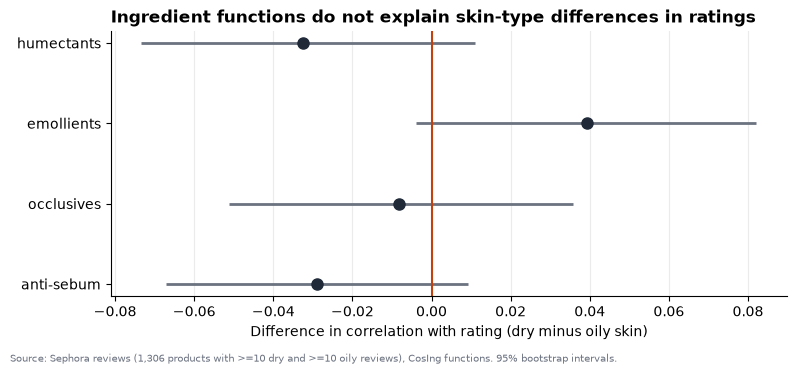

saved 6226 rows


In [9]:
import matplotlib.pyplot as plt

res_b = pd.DataFrame(out)                                          # the bootstrap table from Step 5
res_b = res_b.iloc[::-1]                                           # first feature on top
fig, ax = plt.subplots(figsize=(8, 3.6))
y = range(len(res_b))
ax.hlines(y, res_b["95% CI low"], res_b["95% CI high"], color="#6B7280", linewidth=2)      # 95% interval
ax.plot(res_b["difference (dry - oily)"], y, "o", color="#1F2937", markersize=8)            # observed difference
ax.axvline(0, color="#C2410C", linewidth=1.5)                                               # zero = no difference
ax.set_yticks(list(y)); ax.set_yticklabels(res_b["feature"])
ax.set_xlabel("Difference in correlation with rating (dry minus oily skin)")
ax.set_title("Ingredient functions do not explain skin-type differences in ratings", loc="left", fontsize=12, fontweight="bold")
ax.grid(axis="x", alpha=0.25)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
fig.text(0.01, -0.02, "Source: Sephora reviews (1,306 products with >=10 dry and >=10 oily reviews), CosIng functions. 95% bootstrap intervals.",
         fontsize=7, color="#6B7280")
plt.tight_layout()
plt.savefig("../images/12_h3_difference.png", dpi=200, bbox_inches="tight")
plt.show()

# File for the Tableau "fit" page: one row per product and skin type
tab = pt.merge(prod[["product_id", "product_name", "brand_name", "price_usd", "rating"]], on="product_id", how="left")
tab = tab.rename(columns={"rating": "overall_rating", "mean_rating": "skin_type_rating", "n": "n_reviews_skin_type"})
tab.to_csv("../data/tableau/sephora_skin_fit.csv", index=False)
print("saved", len(tab), "rows")

In [11]:
pd.read_csv("../data/tableau/sephora_skin_fit.csv")

,product_id,skin_type,n_reviews_skin_type,skin_type_rating,n_humectants,n_emollients,n_occlusives,n_ingredients,n_antisebum,share_humectants,share_emollients,share_occlusives,share_antisebum,product_name,brand_name,price_usd,overall_rating
0,P107306,combination,111,4.054054,9,13,2,55,0,0.163636,0.236364,0.036364,0.0,Renewing Eye Cream,Murad,89.0,4.0316
1,P107306,dry,40,4.450000,9,13,2,55,0,0.163636,0.236364,0.036364,0.0,Renewing Eye Cream,Murad,89.0,4.0316
2,P107306,normal,27,4.407407,9,13,2,55,0,0.163636,0.236364,0.036364,0.0,Renewing Eye Cream,Murad,89.0,4.0316
3,P107306,oily,22,2.772727,9,13,2,55,0,0.163636,0.236364,0.036364,0.0,Renewing Eye Cream,Murad,89.0,4.0316
4,P114902,combination,525,4.392381,2,1,0,30,0,0.066667,0.033333,0.000000,0.0,Goodbye Acne Max Complexion Correction Pads,Peter Thomas Roth,48.0,4.4199
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6221,P9940,oily,80,4.237500,7,9,0,45,0,0.155556,0.200000,0.000000,0.0,Essential-C Day Moisture Broad Spectrum SPF 30...,Murad,68.0,4.2485
6222,P9941,combination,200,4.580000,4,1,0,36,0,0.111111,0.027778,0.000000,0.0,Essential-C Cleanser,Murad,44.0,4.4962
6223,P9941,dry,44,4.227273,4,1,0,36,0,0.111111,0.027778,0.000000,0.0,Essential-C Cleanser,Murad,44.0,4.4962
6224,P9941,normal,43,4.534884,4,1,0,36,0,0.111111,0.027778,0.000000,0.0,Essential-C Cleanser,Murad,44.0,4.4962
